# Implementation of GRU Model for Mail workload

In [1]:
import lightgbm as lgb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import accuracy_score

from tqdm import tqdm

## data preprocess
- calculate death time
- calculate previous death time
- calculate frequency
- normalize features

In [2]:
train_fname = '../Overhead_analysis/PHFTL/io_trace/wrap_up/src1_2.csv'

In [6]:
train_trace = pd.read_csv(train_fname, names=['Timestamp', 'Hostname', 'DiskNumber', 'io_type', 'lba', 'io_size', 'ResponseTime'], sep=' ')

In [7]:
## 학습에 불필요한 read io 삭제
train_trace = train_trace[train_trace['io_type'] == 'Write']
train_trace.reset_index(drop=True, inplace=True)
train_trace.head()

,Timestamp,Hostname,DiskNumber,io_type,lba,io_size,ResponseTime
0,128166372013537634,src1,2,Write,166003508,4096,932
1,128166372021662075,src1,2,Write,1169100800,16384,1438
2,128166372021662904,src1,2,Write,1149526016,4096,610
3,128166372021663045,src1,2,Write,1149521920,4096,468
4,128166372023537501,src1,2,Write,1642655744,4096,1000


In [8]:
# define death time calculation function

def dt_calculator(trace):
    dt = [-1] * len(trace)
    lba_dict = dict()
    for i in tqdm(range(len(trace))):
        lba = trace.loc[i, 'lba']

        if lba in lba_dict:
            dt[lba_dict[lba]] = i - lba_dict[lba]
            lba_dict[lba] = i
        else:
            lba_dict[lba] = i

    return dt

In [9]:
train_trace['dt'] = dt_calculator(train_trace)

train_trace.head()

100%|██████████| 1423694/1423694 [00:08<00:00, 175471.43it/s]


,Timestamp,Hostname,DiskNumber,io_type,lba,io_size,ResponseTime,dt
0,128166372013537634,src1,2,Write,166003508,4096,932,21056
1,128166372021662075,src1,2,Write,1169100800,16384,1438,141077
2,128166372021662904,src1,2,Write,1149526016,4096,610,15
3,128166372021663045,src1,2,Write,1149521920,4096,468,36
4,128166372023537501,src1,2,Write,1642655744,4096,1000,27


In [10]:
# define previous death time calculation function

def prev_dt_calculator(trace):
    prev_dt = [-1] * len(trace)

    lba_dict = dict()
    for i in tqdm(range(len(trace))):
        lba = trace.loc[i, 'lba']

        if lba in lba_dict:
            prev_dt[i] = trace.loc[lba_dict[lba], 'dt']
            lba_dict[lba] = i
        else:
            lba_dict[lba] = i
    
    return prev_dt
    

In [11]:
train_trace['prev_dt'] = prev_dt_calculator(train_trace)

  0%|          | 0/1423694 [00:00<?, ?it/s]

100%|██████████| 1423694/1423694 [00:14<00:00, 95531.89it/s] 


In [12]:
# define frequency calculation function

def freq_calculator(trace):
    freq = [0] * len(trace)
    
    lba_dict = dict()
    for i in tqdm(range(len(trace))):
        lba = trace.loc[i, 'lba']

        if lba in lba_dict:
            freq[i] = lba_dict[lba]
            lba_dict[lba] += 1
        else:
            freq[i] = 0
            lba_dict[lba] = 1

    return freq

In [13]:
TRAINING_PERIOD = 300000
SEQUENCE_LENGTH = 5
NUM_GROUPS = 5

In [14]:
train_trace['freq'] = freq_calculator(train_trace)

100%|██████████| 1423694/1423694 [00:07<00:00, 179508.59it/s]


In [15]:
# define MinMax scaler fucntion

def MinMaxScaler(min_value, max_value, value):
    return min(round(((value - min_value) / (max_value - min_value)), 5), 1)

In [16]:
# define log scaler fucntion

def LogScaler(value):
    return np.log1p(value)

In [17]:
train_trace['log_lba'] = LogScaler(train_trace['lba'])
train_trace['log_size'] = LogScaler(train_trace['io_size'])
train_trace['log_freq'] = LogScaler(train_trace['freq'])

In [18]:
train_trace['top8'] = [i >> (32 - 8) & 255 for i in train_trace['lba']]
train_trace['bot8'] = [i & 255 for i in train_trace['lba']]
train_trace['top16'] = [i >> (32 - 16) & 65535 for i in train_trace['lba']]
train_trace['bot16'] = [i & 65535 for i in train_trace['lba']]

In [19]:
train_trace['log_top16'] = LogScaler(train_trace['top16'])
train_trace['log_bot16'] = LogScaler(train_trace['bot16'])

In [20]:
train_trace

,Timestamp,Hostname,DiskNumber,io_type,lba,io_size,ResponseTime,dt,prev_dt,freq,log_lba,log_size,log_freq,top8,bot8,top16,bot16,log_top16,log_bot16
0,128166372013537634,src1,2,Write,166003508,4096,932,21056,-1,0,18.927519,8.318010,0.000000,9,52,2533,820,7.837554,6.710523
1,128166372021662075,src1,2,Write,1169100800,16384,1438,141077,-1,0,20.879501,9.704122,0.000000,69,0,17839,4096,9.789198,8.318010
2,128166372021662904,src1,2,Write,1149526016,4096,610,15,-1,0,20.862616,8.318010,0.000000,68,0,17540,24576,9.772296,10.109566
3,128166372021663045,src1,2,Write,1149521920,4096,468,36,-1,0,20.862612,8.318010,0.000000,68,0,17540,20480,9.772296,9.927253
4,128166372023537501,src1,2,Write,1642655744,4096,1000,27,-1,0,21.219580,8.318010,0.000000,97,0,25064,61440,10.129228,11.025833
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1423689,128172419954501129,src1,2,Write,1078034432,4096,1671,-1,53,11523,20.798405,8.318010,9.352187,64,0,16449,32768,9.708081,10.397238
1423690,128172419954501537,src1,2,Write,1173692416,4096,1263,-1,55,11855,20.883421,8.318010,9.380589,69,0,17909,8192,9.793114,9.011035
1423691,128172419963251401,src1,2,Write,1171726336,12288,1342,-1,49525,15,20.881744,9.416460,2.772589,69,0,17879,8192,9.791438,9.011035
1423692,128172419963252105,src1,2,Write,1149530112,4096,638,-1,10,62157,20.862619,8.318010,11.037435,68,0,17540,28672,9.772296,10.263711


In [21]:
# train_trace['rank_freq'] = 
# train_trace['rank_prevDT'] = []
rank_freq = []
rank_set = set()
rank_sorted = []
for i in tqdm(range(len(train_trace))):
    f = train_trace.loc[i, 'freq']
    if f in rank_set:
        rank_freq.append(rank_sorted.index(f))
    else:
        rank_set.add(f)
        rank_sorted.append(f)
        rank_freq.append(rank_sorted.index(f))

train_trace['rank_freq'] = rank_freq

100%|██████████| 1423694/1423694 [01:55<00:00, 12326.82it/s]


In [22]:
print(sorted(set(train_trace['freq'])) == rank_sorted)

True


In [23]:
train_trace['log_rank_freq'] = LogScaler(train_trace['rank_freq'])

In [24]:
# get trainable trace by training period
def get_trainable_trace(trace, period, n_groups, start_index):
    features = []
    dts = []
    category_bound = []

    i = start_index
    for j in tqdm(range(period)):
        io_index = i + j
        dt = trace.loc[io_index, 'dt']
        if dt > -1 and j + dt < period:
            features.append([trace.loc[io_index, 'lba'], 
                trace.loc[io_index, 'rank_freq'],
                trace.loc[io_index, 'top16'], 
                trace.loc[io_index, 'bot16'], 
                trace.loc[io_index, 'rank_freq'],
                trace.loc[io_index, 'io_size'],
                trace.loc[io_index, 'freq'],
                trace.loc[io_index, 'prev_dt']])
            dts.append(trace.loc[io_index, 'dt'])

    category_bound = list(np.percentile(np.array(dts), [int(100/n_groups) * i for i in range(1, n_groups)] + [100]))
    
    for i in range(len(dts)):
        for j in range(n_groups):
            if dts[i] <= category_bound[j]:
                dts[i] = j
                break
        
        for j in range(n_groups):
            if features[i][-1] > -1 and features[i][-1] <= category_bound[j]:
                features[i][-1] = j
                break

    return features, dts, category_bound

In [25]:
# get test trace by training period
def get_test_trace(trace, period, n_groups, category_bound, start_index):
    features = []
    dts = []

    i = start_index
    for j in tqdm(range(period)):
        io_index = i + j
        dt = trace.loc[io_index, 'dt']
        if dt > -1 and dt < period:
            features.append([trace.loc[io_index, 'lba'], 
                trace.loc[io_index, 'rank_freq'],
                trace.loc[io_index, 'top16'], 
                trace.loc[io_index, 'bot16'], 
                trace.loc[io_index, 'rank_freq'],
                trace.loc[io_index, 'io_size'],
                trace.loc[io_index, 'freq'],
                trace.loc[io_index, 'prev_dt']])
            dts.append(trace.loc[io_index, 'dt'])
    
    for i in range(len(dts)):
        if dts[i] > 0:
            for j in range(n_groups):
                if dts[i] <= category_bound[j]:
                    dts[i] = j
                    break
            if dts[i] >= n_groups:
                dts[i] = n_groups - 1 
        else:
            dts[i] = n_groups - 1

        for j in range(n_groups):
            if features[i][-1] > -1 and features[i][-1] <= category_bound[j]:
                features[i][-1] = j
                break

    return features, dts

In [26]:
# get test trace by training period
def get_test_trace_not_trained(trace, period, n_groups, category_bound, start_index):
    features = []
    dts = []

    i = start_index
    for j in tqdm(range(period)):
        io_index = i + j
        dt = trace.loc[io_index, 'dt']
        if dt == -1 or dt >= period:
            features.append([trace.loc[io_index, 'lba'], 
                trace.loc[io_index, 'rank_freq'],
                trace.loc[io_index, 'top16'], 
                trace.loc[io_index, 'bot16'], 
                trace.loc[io_index, 'rank_freq'],
                trace.loc[io_index, 'io_size'],
                trace.loc[io_index, 'freq'],
                trace.loc[io_index, 'prev_dt']])
            dts.append(trace.loc[io_index, 'dt'])
    
    for i in range(len(dts)):
        if dts[i] > 0:
            for j in range(n_groups):
                if dts[i] <= category_bound[j]:
                    dts[i] = j
                    break
            if dts[i] >= n_groups:
                dts[i] = n_groups - 1 
        else:
            dts[i] = n_groups - 1
         
        for j in range(n_groups):
            if features[i][-1] > -1 and features[i][-1] <= category_bound[j]:
                features[i][-1] = j
                break

    return features, dts

In [27]:
train_feature = []
train_dt = []
category_bounds = []

for i in range(len(train_trace)//TRAINING_PERIOD):
    tmp_feature, tmp_dt, tmp_bound = get_trainable_trace(train_trace, TRAINING_PERIOD, NUM_GROUPS, i * TRAINING_PERIOD)
    train_feature.append(tmp_feature)
    train_dt.append(tmp_dt)
    category_bounds.append(tmp_bound)

100%|██████████| 300000/300000 [00:12<00:00, 23495.89it/s]


In [28]:
category_bounds

[[772.0, 1538.0, 2776.0, 7653.0, 294752.0],
 [48.0, 1046.0, 2416.0, 9186.0, 289970.0],
 [30.0, 635.0, 1882.0, 4641.0, 294187.0],
 [13.0, 47.0, 847.0, 5068.0, 287269.0]]

In [29]:
for i in range(len(train_dt)):
    print(len(train_dt[i]))

252030
244751
260322
250503


In [51]:
test_feature = []
test_dt = []

for i in range(1, len(train_trace)//TRAINING_PERIOD+1):
    tmp_feature, tmp_dt = get_test_trace(train_trace, TRAINING_PERIOD, NUM_GROUPS, category_bounds[i-1], i * TRAINING_PERIOD)
    test_feature.append(tmp_feature)
    test_dt.append(tmp_dt)

 75%|███████▍  | 223694/300000 [00:10<00:03, 22203.81it/s]


KeyError: 1423694

In [ ]:
from collections import Counter

test_feature_not_trained = []
test_dt_not_trained = []

for i in range(1, len(train_trace)//TRAINING_PERIOD+1):
    tmp_feature, tmp_dt = get_test_trace_not_trained(train_trace, TRAINING_PERIOD, NUM_GROUPS, category_bounds[i-1], i * TRAINING_PERIOD)
    test_feature_not_trained.append(tmp_feature)
    test_dt_not_trained.append(tmp_dt)
    print(Counter(tmp_dt))

100%|██████████| 300000/300000 [00:03<00:00, 92976.00it/s] 


Counter({4: 37172})


100%|██████████| 300000/300000 [00:02<00:00, 107291.67it/s]


Counter({4: 26582})


100%|██████████| 300000/300000 [00:03<00:00, 95297.14it/s] 

Counter({4: 35942})


## Train & Evaluation

In [32]:
params = {
            'objective': 'multiclass', 'num_class': NUM_GROUPS,
            'metric': 'multi_logloss', 'learning_rate': 0.05,
            'num_leaves': 127, 'min_child_samples': 20,
            'feature_fraction': 0.8, 'bagging_fraction': 0.8,
            'bagging_freq': 5, 'lambda_l1': 0.1, 'lambda_l2': 0.1,
            'verbose': -1, 'n_jobs': -1,
        }

In [53]:
acc_l = []
acc_l_not_trained = []
precision_l = []
recall_l = []
f1_l = []
results = []
for i in range(len(train_trace)//TRAINING_PERIOD):
    dataset = lgb.Dataset(np.array(train_feature[i]), label=train_dt[i])

    model = lgb.train(params, dataset)
    prediction = model.predict(np.array(test_feature[i]))
    acc_l.append(accuracy_score(test_dt[i], [np.argmax(i) for i in prediction]))

    result = model.predict(train_trace[['lba', 'rank_freq', 'top16', 'bot16', 'rank_freq', 'io_size', 'freq', 'prev_dt']][i * TRAINING_PERIOD: min((i + 1) * TRAINING_PERIOD, len(train_trace))])
    result = [np.argmax(i) for i in result]

    results.append(result)
    acc_l_not_trained.append(accuracy_score(test_dt_not_trained[i], [np.argmax(i) for i in model.predict(test_feature_not_trained[i])]))
    print(f"accuracy with trained range : {acc_l[-1]}, accuracy with not trained range : {acc_l_not_trained[-1]}")
    model.save_model(f'lgb_src1_2_{i}.txt')

accuracy with trained range : 0.553320042004657, accuracy with not trained range : 0.7791079307005273
accuracy with trained range : 0.5822220921812024, accuracy with not trained range : 0.7819953351892258
accuracy with trained range : 0.638109809208583, accuracy with not trained range : 0.7290913137833176


IndexError: list index out of range

In [61]:
for i in range(5):
    print(len(results[i]))

300000
300000
300000
223694


IndexError: list index out of range

In [57]:
result = model.predict(train_trace[['lba', 'rank_freq', 'top16', 'bot16', 'rank_freq', 'io_size', 'freq', 'prev_dt']][1200000:])
result = [np.argmax(i) for i in result]

In [59]:
len(result)

223694

In [60]:
results.append(result)

In [62]:
tmp = pd.read_csv('lgb_infer_src1_2.txt', names=['class', 'infer_time'], sep=' ')

In [64]:
infered_class = results[0] + results[1] + results[2] + results[3]

In [65]:
len(infered_class)

1123694

In [66]:
tmp['class'][300000:] = infered_class

/tmp/ipykernel_611346/2454991320.py:1: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  tmp['class'][300000:] = infered_class
/tmp/ipykernel_611346/2454991320.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from 

In [67]:
tmp

,class,infer_time
0,3,0.000
1,1,0.000
2,2,0.000
3,0,0.000
4,3,0.000
...,...,...
1423689,3,15.353
1423690,2,15.367
1423691,4,15.443
1423692,0,15.437


In [79]:
tmp["infer_time"][300000:].mean()

19.236594744654695

In [80]:
print(min(tmp["infer_time"][300000:]), max(tmp["infer_time"][300000:]))

14.462 2704.371


In [73]:
src_trace = pd.read_csv('../Overhead_analysis/PHFTL/io_trace/prediction/src1_2.csv', names=['tp', 'lba', 'size', 'op', 'gid'], sep=' ')
wc = 0
gid = [-1] * len(src_trace)
infer_time = [-1] * len(src_trace)
for i in range(len(src_trace)):
    op = src_trace.loc[i, 'op']
    if op == 1:
        gid[i] = tmp.loc[wc, 'class']
        infer_time[i] = tmp.loc[wc, 'infer_time']
        wc += 1

In [74]:
wc

1423694

In [75]:
src_trace['gid'] = gid
src_trace['infer_time'] = infer_time

In [76]:
src_trace

,tp,lba,size,op,gid,infer_time
0,128166372003663869,512033792,24576,0,-1,-1.000
1,128166372013448586,89289524,4096,0,-1,-1.000
2,128166372013537634,166003508,4096,1,3,0.000
3,128166372021662075,1169100800,16384,1,1,0.000
4,128166372021662904,1149526016,4096,1,2,0.000
...,...,...,...,...,...,...
1907768,128172419954501537,1173692416,4096,1,2,15.367
1907769,128172419963251401,1171726336,12288,1,4,15.443
1907770,128172419963252105,1149530112,4096,1,0,15.437
1907771,128172419963252218,1149517824,4096,1,2,15.324


In [78]:
src_trace.to_csv('fadt_src1_2_cpu.csv', header=False, index=False, sep=' ')

In [46]:
total_accuracy = [int(acc_l[i] * len(test_feature[i]) + acc_l_not_trained[i] * len(test_feature_not_trained[i])) for i in range(len(train_trace)//TRAINING_PERIOD - 1)]
print(f"total accuracy : {round(sum(total_accuracy)/(TRAINING_PERIOD * len(total_accuracy)) * 100, 3)}%")

total accuracy : 61.008%


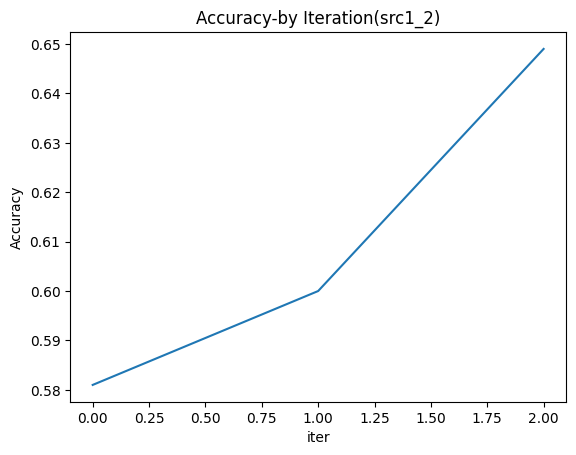

In [47]:
plt.plot([i for i in range(len(acc_l))], [round(v / (len(test_feature[i])+len(test_feature_not_trained[i])), 3) for i, v in enumerate(total_accuracy)])
plt.xlabel('iter')
plt.ylabel('Accuracy')
plt.title('Accuracy-by Iteration(src1_2)')
plt.show()

# plt.plot([i for i in range(len(acc_l_not_trained))], acc_l_not_trained)
# plt.xlabel('iter')
# plt.ylabel('Accuracy')
# plt.title('Accuracy with not trained range')
# plt.show()


# plt.plot([i for i in range(len(precision_l))], precision_l)
# plt.xlabel('iter')
# plt.ylabel('precision')
# plt.title('precision')
# plt.show()

# plt.plot([i for i in range(len(recall_l))], recall_l)
# plt.xlabel('iter')
# plt.ylabel('recall')
# plt.title('recall')
# plt.show()

# plt.plot([i for i in range(len(f1_l))], f1_l)
# plt.xlabel('iter')
# plt.ylabel('F1')
# plt.title('F1')
# plt.show()

Average Accuracy with trained range : 0.591
Average Accuracy with not trained range : 0.763


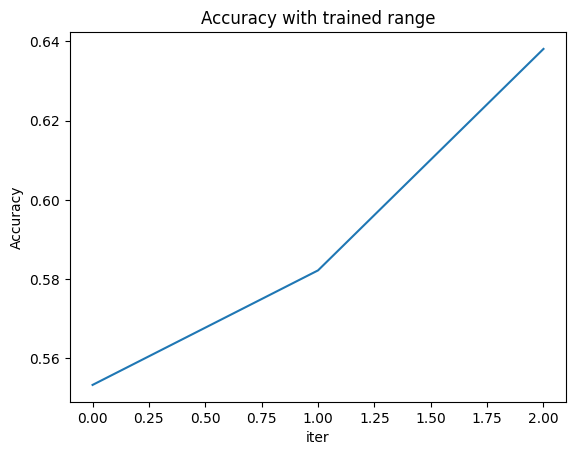

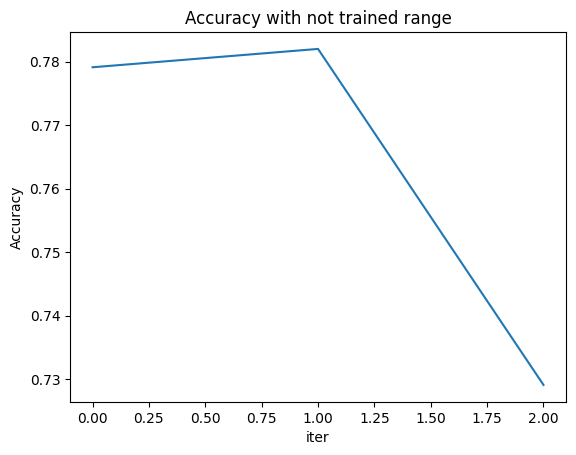

In [42]:
print(f'Average Accuracy with trained range : {round(sum(acc_l)/len(acc_l), 3)}')
print(f'Average Accuracy with not trained range : {round(sum(acc_l_not_trained)/len(acc_l_not_trained), 3)}')


plt.plot([i for i in range(len(acc_l))], acc_l)
plt.xlabel('iter')
plt.ylabel('Accuracy')
plt.title('Accuracy with trained range')
plt.show()

plt.plot([i for i in range(len(acc_l_not_trained))], acc_l_not_trained)
plt.xlabel('iter')
plt.ylabel('Accuracy')
plt.title('Accuracy with not trained range')
plt.show()


# plt.plot([i for i in range(len(precision_l))], precision_l)
# plt.xlabel('iter')
# plt.ylabel('precision')
# plt.title('precision')
# plt.show()

# plt.plot([i for i in range(len(recall_l))], recall_l)
# plt.xlabel('iter')
# plt.ylabel('recall')
# plt.title('recall')
# plt.show()

# plt.plot([i for i in range(len(f1_l))], f1_l)
# plt.xlabel('iter')
# plt.ylabel('F1')
# plt.title('F1')
# plt.show()

In [43]:
train_trace[['lba', 'rank_freq', 'top16', 'bot16', 'rank_freq', 'io_size', 'freq', 'prev_dt']].to_csv('src1_2_c_infer.csv', header=False, index=False)

In [44]:
len(train_trace)

1423694